# RASCALS / Original measured LinuxONE service data

This experiment records real request timings, process counters and timestamps. It deliberately separates measured service data from the synthetic hospital-service simulator. A bounded CPU-computation change is annotated; no actual hospital incident is claimed.

In [1]:
from pathlib import Path
import os,sys,platform,json
ROOT=Path.cwd()
if not (ROOT/'continuityguard').is_dir():ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
assert platform.machine()=='s390x'
print('Actual kernel:',platform.machine(),platform.python_version())


Actual kernel: s390x 3.12.15


In [2]:
from continuityguard.measured_workload import main
observed=main(ROOT)

Measured phase baseline_fit


Measured phase baseline_check


Measured phase controlled_compute_pressure


Measured phase recovery


{
  "architecture": "s390x",
  "collected_utc": "2026-10-17T11:33:58.809470+00:00",
  "data_kind": "Original measured service timings and process counters on the assigned LinuxONE VM",
  "csv_sha256": "03de08d83fd5a646959e0c5ce9555d22d5c60c00f740c94d97c1a76255b6574b",
  "rows": 64,
  "features": [
    "request_latency_p95_ms",
    "process_cpu_percent"
  ],
  "model": "IsolationForest, 100 trees, 30 baseline observations; 95th-percentile fit-only cutoff",
  "phase_results": {
    "baseline_fit": {
      "observations": 30,
      "median_request_p95_ms": 0.9986075,
      "above_baseline_cutoff": 2,
      "failed_requests": 0
    },
    "baseline_check": {
      "observations": 10,
      "median_request_p95_ms": 0.975139,
      "above_baseline_cutoff": 0,
      "failed_requests": 0
    },
    "controlled_compute_pressure": {
      "observations": 12,
      "median_request_p95_ms": 81.641808,
      "above_baseline_cutoff": 12,
      "failed_requests": 0
    },
    "recovery": {
      "obs

,observed_utc,phase_annotation,requests,failures,request_latency_p95_ms,process_cpu_percent,process_rss_bytes,vm_memory_percent,observation_seconds,novelty_score,above_baseline_cutoff
0,2026-10-17T11:33:26.638025+00:00,baseline_fit,4,0,8.750202,0.0,153899008,40.6,0.011199,0.827202,True
1,2026-10-17T11:33:27.129471+00:00,baseline_fit,4,0,0.989310,0.0,153899008,40.6,0.002113,0.331665,False
2,2026-10-17T11:33:27.630057+00:00,baseline_fit,4,0,0.983751,0.0,153899008,40.6,0.002026,0.329193,False
3,2026-10-17T11:33:28.130921+00:00,baseline_fit,4,0,1.161387,0.0,153899008,40.6,0.002278,0.533246,False
4,2026-10-17T11:33:28.631406+00:00,baseline_fit,4,0,0.993003,0.0,153899008,40.6,0.002127,0.333088,False
...,...,...,...,...,...,...,...,...,...,...,...
59,2026-10-17T11:33:56.168821+00:00,recovery,4,0,1.006504,0.0,153899008,40.9,0.002064,0.341481,False
60,2026-10-17T11:33:56.669546+00:00,recovery,4,0,1.030689,0.0,153899008,40.9,0.002121,0.382172,False
61,2026-10-17T11:33:57.170152+00:00,recovery,4,0,1.017296,0.0,153899008,40.9,0.002106,0.350826,False
62,2026-10-17T11:33:57.670768+00:00,recovery,4,0,1.029923,0.0,153899008,40.9,0.002115,0.379058,False


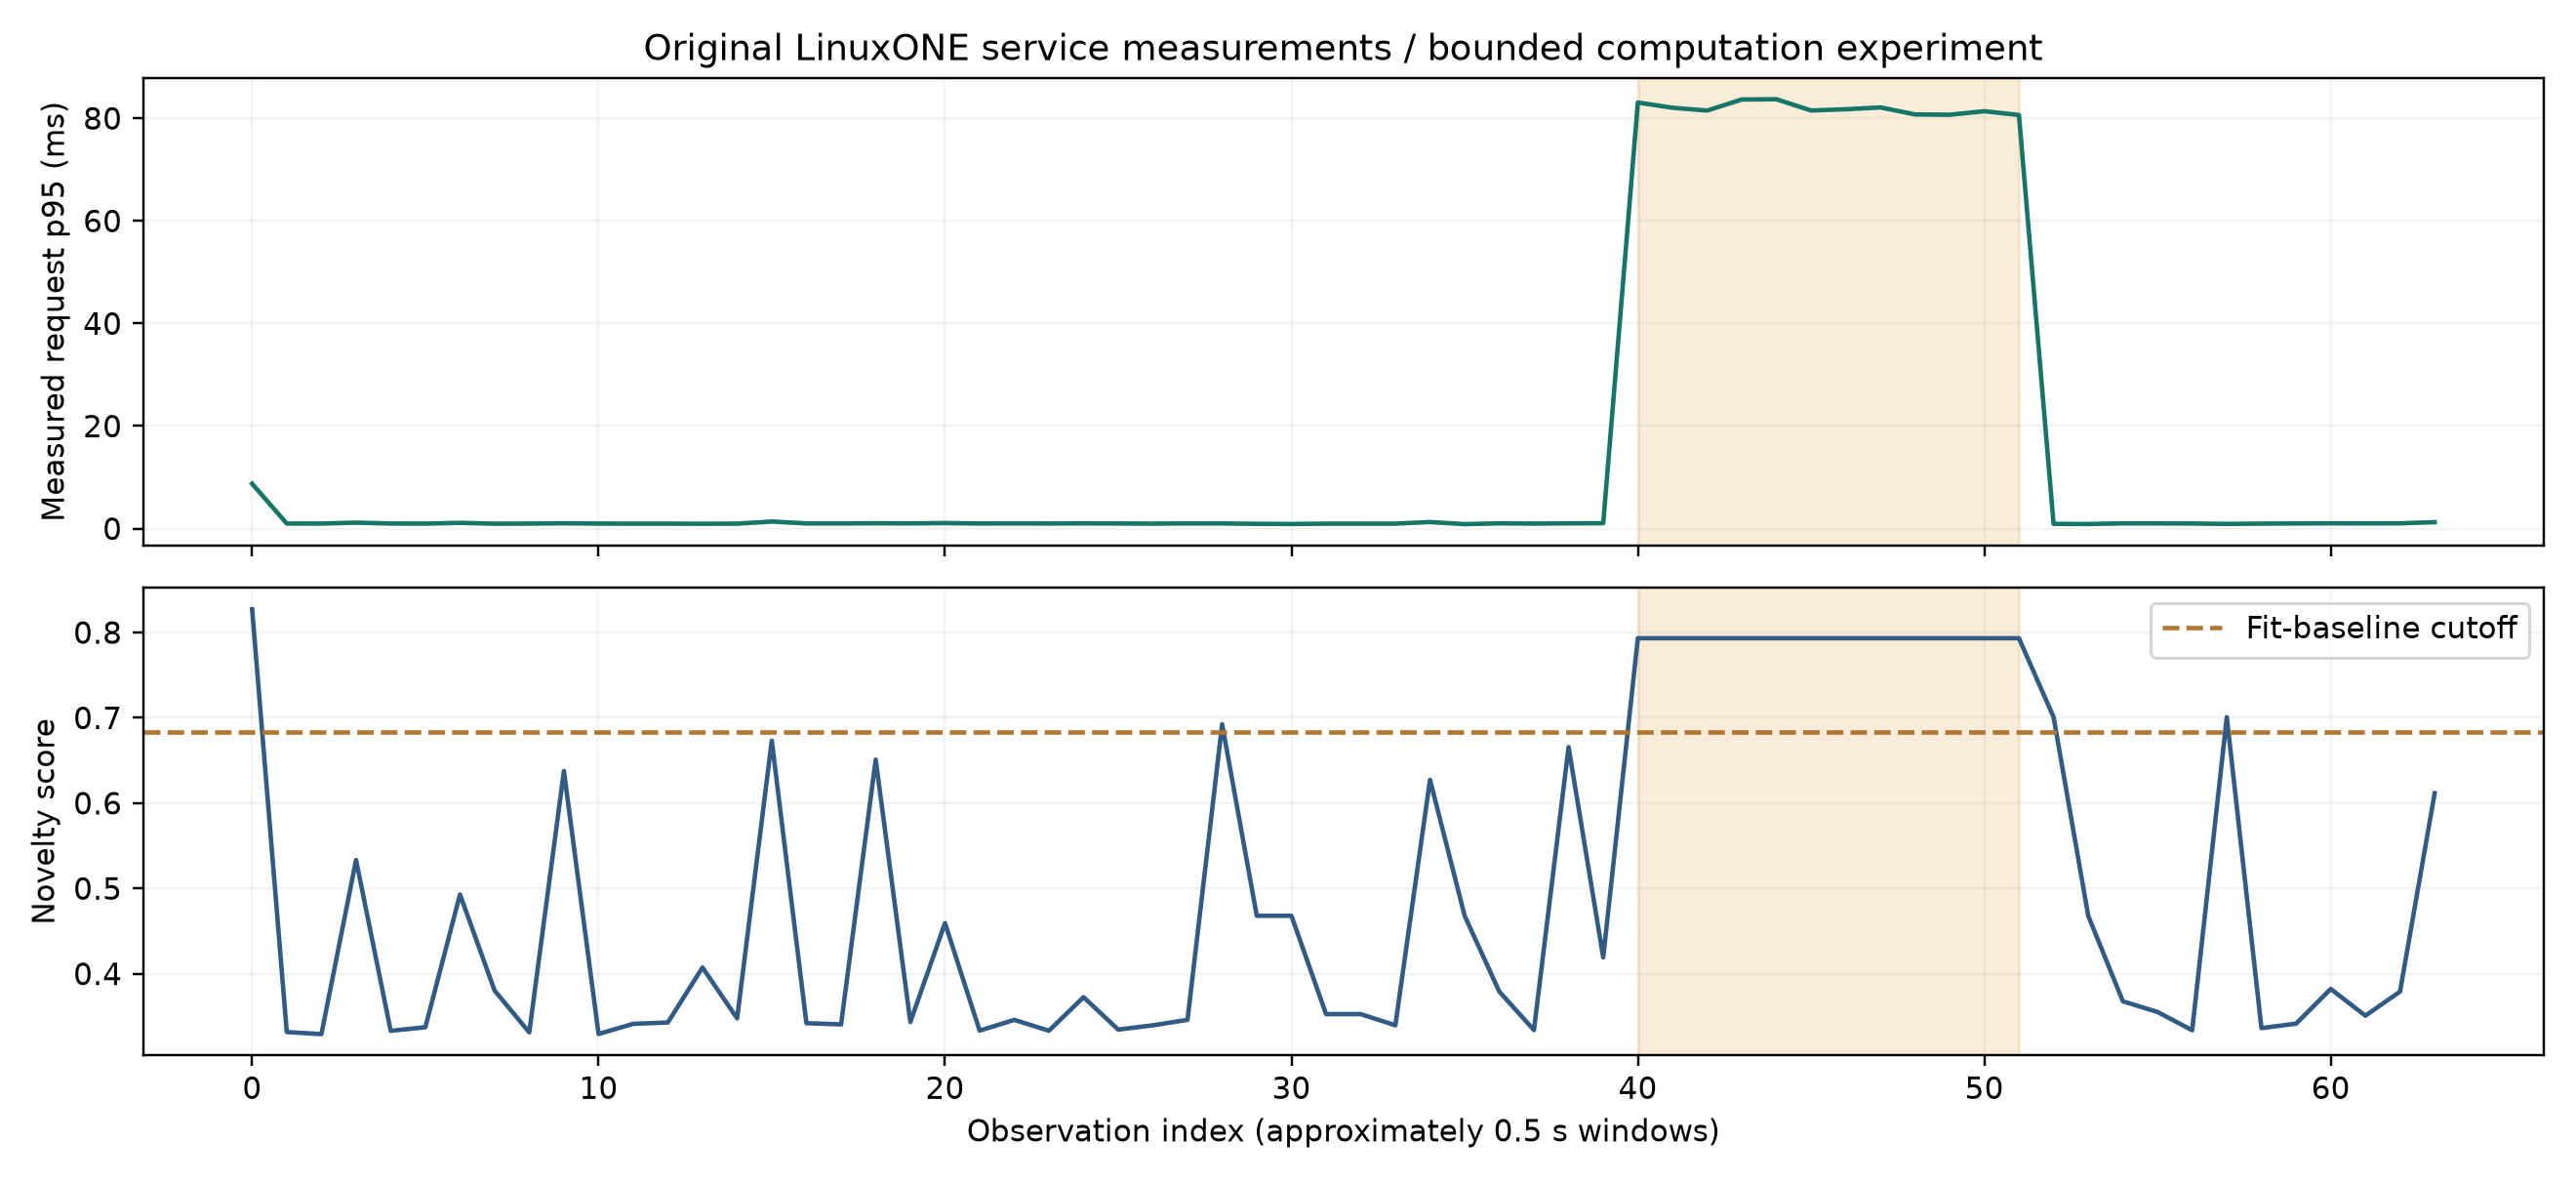

Measured-data provenance: 03de08d83fd5a646959e0c5ce9555d22d5c60c00f740c94d97c1a76255b6574b


In [3]:
import pandas as pd
from IPython.display import display,Image
display(pd.read_csv(ROOT/'artifacts/measured/original-linuxone-service.csv'))
display(Image(filename=str(ROOT/'artifacts/measured/observed-service.png')))
print('Measured-data provenance:',observed['csv_sha256'])